In [3]:
import os
from datetime import date, timedelta
from zoneinfo import ZoneInfo

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pandas_market_calendars as mcal

## Notes

- SPXW, 0–30 DTE, December 2025–August 2026
- We use a gamma proxy because call is assumed positive and puts assumed negative.

In [4]:
MINIO_ENDPOINT='localhost:9000'
MINIO_ACCESS_KEY='minioadmin'
MINIO_SECRET_KEY='minioadmin'
MINIO_STAGING_BUCKET='tickrake-staging'
MINIO_CACHE_BUCKET='tractatus-lakehouse'
MINIO_ICEBERG_BUCKET='tractatus-iceberg'
CT = ZoneInfo("America/Chicago")

def get_duckdb_conn() -> duckdb.DuckDBPyConnection:
    """Return a DuckDB connection configured for MinIO S3 access."""
    con = duckdb.connect()
    con.execute(f"""
        SET s3_endpoint        = '{MINIO_ENDPOINT}';
        SET s3_url_style       = 'path';
        SET s3_access_key_id   = '{MINIO_ACCESS_KEY}';
        SET s3_secret_access_key = '{MINIO_SECRET_KEY}';
        SET s3_use_ssl         = false;
    """)
    return con

def parquet_uri(sample_date: date, root: str = "SPXW", provider: str = "schwab") -> str:
    """Path pattern: s3://tractatus-lakehouse/options/{provider}/YYYY/MM/DD/{root}_samples_YYYY-MM-DD.parquet"""
    return (
        f"s3://tractatus-lakehouse/options/{provider}"
        f"/{sample_date.year}/{sample_date.month:02d}/{sample_date.day:02d}"
        f"/{root}_samples_{sample_date}.parquet"
    )

con = get_duckdb_conn()

## Data

In [5]:
schedule = mcal.get_calendar('NYSE').schedule(
    start_date='2025-12-01',
    end_date='2026-11-17'
)
session_map = pd.DataFrame(index=schedule.index)
session_map.index.name = 'outcome_date'

session_map['source_date'] = session_map.index.to_series().shift(1)
session_map['calendar_dte'] = (
    session_map.index.to_series() - session_map['source_date']
).dt.days

session_map = session_map.loc['2026-01-02':]
session_map.head()

,source_date,calendar_dte
outcome_date,,
2026-01-02,2025-12-31,2.0
2026-01-05,2026-01-02,3.0
2026-01-06,2026-01-05,1.0
2026-01-07,2026-01-06,1.0
2026-01-08,2026-01-07,1.0


In [6]:
df = con.execute(f"""
    SELECT
        contract_type,
        underlying_symbol,
        underlying_price,
        symbol,
        option_root,
        strike,
        expiration_date,
        last,
        last_size,
        mark,
        bid,
        bid_size,
        ask,
        ask_size,
        open_interest,
        total_volume,
        volatility,
        theoretical_volatility,
        delta,
        gamma,
        theta,
        vega,        
        sampled_at,
        CAST(timezone('America/Chicago', sampled_at) AS DATE) AS sample_date
    FROM read_parquet('s3://tractatus-lakehouse/options/schwab/2026/*/*/SPXW_samples_*.parquet')
    WHERE expiration_date >= CAST(timezone('America/Chicago', sampled_at) AS DATE)
    AND timezone('America/Chicago', sampled_at) > TIMESTAMP '2026-01-01 00:00:00'
    AND timezone('America/Chicago', sampled_at) < TIMESTAMP '2026-11-20 00:00:00'
    AND CAST(timezone('America/Chicago', sampled_at) AS TIME) >= TIME '08:30:00'
    AND CAST(timezone('America/Chicago', sampled_at) AS TIME) < TIME '09:30:00'
    QUALIFY sampled_at = MIN(sampled_at) OVER (PARTITION BY expiration_date, CAST(timezone('America/Chicago', sampled_at) AS DATE))
""").df()
# WHERE CAST(timezone('America/Chicago', sampled_at) AS DATE) = expiration_date
# expiration_date - CAST(timezone('America/Chicago', sampled_at) AS DATE) <= 30
# Parse sampled_at as a timezone-aware UTC timestamp, then convert to CT.
df["sampled_at"] = pd.to_datetime(df["sampled_at"], utc=True)
df["sampled_at_ct"] = df["sampled_at"].dt.tz_convert(CT)
df.groupby('expiration_date').count()
print(f"Loaded {len(df):,} rows, {df['sampled_at'].nunique()} snapshots.")
print(f"Min sampled_at {df['sampled_at'].min()}")
print(f"Max sampled_at {df['sampled_at'].max()}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Loaded 2,070,958 rows, 788 snapshots.
Min sampled_at 2026-01-02 14:40:01+00:00
Max sampled_at 2026-11-23 14:32:27+00:00


In [7]:
es_dly = pd.read_csv(
    "../../data/candles/es_daily.csv",
    parse_dates=["datetime"],
)
es_dly['datetime'] = (
    pd.to_datetime(es_dly['datetime'], utc=True)
    .dt.tz_convert('America/Chicago')
)
es_dly['sample_date'] = es_dly['datetime'].dt.tz_localize(None).dt.normalize()
es_dly = es_dly.set_index('sample_date').sort_index()
assert es_dly.index.is_unique, "Duplicate ES session dates"

es_dly['es_vol_units'] = es_dly['volume'] * 50

es_dly['avg_vol_21'] = (
    es_dly['es_vol_units']
    .rolling(21, min_periods=21)
    .mean()
    .shift(1)
)
es_dly.head(10)

,datetime,open,high,low,close,volume,es_vol_units,avg_vol_21
sample_date,,,,,,,,
2025-01-02,2025-01-02 00:00:00-06:00,5949.25,5995.25,5874.75,5920.00,1723792,86189600,NaN
2025-01-03,2025-01-03 00:00:00-06:00,5921.00,5996.75,5911.25,5985.25,1145157,57257850,NaN
2025-01-06,2025-01-06 00:00:00-06:00,5994.50,6068.25,5980.75,6028.25,1460382,73019100,NaN
2025-01-07,2025-01-07 00:00:00-06:00,6028.00,6045.50,5935.00,5954.75,1685643,84282150,NaN
2025-01-08,2025-01-08 00:00:00-06:00,5955.50,5975.00,5917.00,5954.75,1702891,85144550,NaN
2025-01-10,2025-01-10 00:00:00-06:00,5943.75,5959.25,5845.25,5861.50,2006438,100321900,NaN
2025-01-13,2025-01-13 00:00:00-06:00,5864.50,5883.25,5809.00,5881.75,1699554,84977700,NaN
2025-01-14,2025-01-14 00:00:00-06:00,5887.25,5918.50,5842.50,5891.50,1779243,88962150,NaN
2025-01-15,2025-01-15 00:00:00-06:00,5891.50,6001.25,5879.50,5987.75,1559024,77951200,NaN


In [8]:
spx_df = pd.read_parquet('../../data/candles/spx_5min_2026.parquet')
spx_df['datetime'] = pd.to_datetime(spx_df['datetime'], utc=True).dt.tz_convert('America/Chicago')
spx_df = spx_df.set_index('datetime').sort_index()
spx_df = spx_df.between_time('08:30', '15:00')

post_first_hr = spx_df[spx_df.index.time == pd.Timestamp('09:30:00').time()]
last_hr = spx_df[spx_df.index.time == pd.Timestamp('15:00:00').time()]
# daily_close = spx_df.groupby(spx_df.index.date)['close'].last()
daily_close = spx_df.groupby(spx_df.index.date)['close'].last()
daily_open = post_first_hr.groupby(post_first_hr.index.date)['open'].first()
abs_dly_ret = (daily_close / daily_open - 1).abs().rename('ret_post_first_hour')

In [9]:
iv_chain = df.copy()
iv_chain['source_date'] = pd.to_datetime(iv_chain['sample_date'])
iv_chain['expiration_date'] = pd.to_datetime(iv_chain['expiration_date'])

iv_chain = iv_chain[
    iv_chain['expiration_date'] == iv_chain['source_date']
].copy()

dist = (iv_chain['strike'] - iv_chain['underlying_price']).abs()
nearest = dist.groupby(iv_chain['source_date']).transform('min')

source_iv = (
    iv_chain.loc[dist == nearest].groupby('source_date')['volatility']
    .mean().rename('prev_atm_iv')
)

In [10]:
chains = df.copy()
chains['source_date'] = pd.to_datetime(chains['sample_date'])
chains['expiration_date'] = pd.to_datetime(chains['expiration_date'])

mapping = session_map.reset_index()[['outcome_date', 'source_date']]
matched = chains.merge(mapping, on='source_date', how='inner', validate='many_to_one')

chains_1dte = matched[matched['expiration_date'] == matched['outcome_date']].copy()
chains_1dte_plus = matched[matched['expiration_date'] > matched['source_date']].copy()

for name, data in [('1DTE', chains_1dte), ('1DTE+', chains_1dte_plus)]:
    print(name, 'rows: ', len(data), 'outcome dates: ', data['outcome_date'].nunique())

1DTE rows:  113624 outcome dates:  201
1DTE+ rows:  1871346 outcome dates:  201


In [11]:
for name, data in [('1DTE', chains_1dte), ('1DTE+', chains_1dte_plus)]:
    bad_gamma = ~np.isfinite(data['gamma']) | (data['gamma'] < 0)

    zero_oi = bad_gamma & data['open_interest'].eq(0)
    unresolved = bad_gamma & ~data['open_interest'].eq(0)

    print(
        name,
        "\n  Invalid gamma, zero OI:", zero_oi.sum(),
        "\n  Invalid gamma, unresolved exposure:", unresolved.sum(),
        "\n  Affected outcome dates:",
        data.loc[unresolved, "outcome_date"].nunique(),
    )

1DTE 
  Invalid gamma, zero OI: 930 
  Invalid gamma, unresolved exposure: 369 
  Affected outcome dates: 4
1DTE+ 
  Invalid gamma, zero OI: 29223 
  Invalid gamma, unresolved exposure: 8991 
  Affected outcome dates: 16


## Gamma Exposure

In [12]:
def add_iv(imbalance, source_iv):
    return (
        imbalance.reset_index()
        .merge(
            source_iv,
            left_on='source_date',
            right_index=True,
            how='left',
            validate='many_to_one'
        )
        .set_index('outcome_date')
        .sort_index()
    )

In [13]:
def daily_numerator(data):
    data = data.copy()
    fields = ['gamma', 'open_interest', 'underlying_price', 'strike']

    invalid = ~np.isfinite(data[fields]).all(axis=1)
    invalid |= (data[['gamma', 'open_interest']] < 0).any(axis=1)
    invalid |= data['underlying_price'].le(0)

    zero_oi = data['open_interest'].eq(0)
    bad_dates = data.loc[
        invalid & ~zero_oi, 'outcome_date'
    ].unique()

    clean = data[~data['outcome_date'].isin(bad_dates) & ~(invalid & zero_oi)].copy()

    sign = clean['contract_type'].map({'CALL': 1, 'PUT': -1})
    assert sign.notna().all(), 'unexpected contract type'

    clean['gamma_numr'] = (
        sign * clean['gamma'] * clean['open_interest'] * 100 * clean['underlying_price']
    )

    return clean.groupby(['outcome_date', 'source_date'])['gamma_numr'].sum(min_count=1).to_frame()

In [14]:
def normalize_exposure(numerator, es_dly):
    result = numerator.reset_index().merge(
        es_dly[['avg_vol_21']],
        left_on='source_date',
        right_index=True,
        how='left',
        validate='many_to_one'
    )

    result['gamma_imbl'] = result['gamma_numr'] / result['avg_vol_21']

    return result.set_index('outcome_date').sort_index()

In [15]:
numerator_1dte = daily_numerator(chains_1dte)
numerator_1dte_plus = daily_numerator(chains_1dte_plus)

In [16]:
imbalance_1dte = normalize_exposure(numerator_1dte, es_dly)
imbalance_1dte_plus = normalize_exposure(numerator_1dte_plus, es_dly)

In [17]:
imbalance_1dte = add_iv(imbalance_1dte, source_iv)
imbalance_1dte_plus = add_iv(imbalance_1dte_plus, source_iv)

In [18]:
# NOTE: create 5min autocorrelation

session = spx_df.between_time('08:30', '15:00').sort_index().copy()
session['outcome_date'] = session.index.tz_localize(None).normalize()

session['ret_5m'] = session.groupby('outcome_date')['close'].transform(
    lambda prices: np.log(prices).diff()
)

dly_ac = (
    session.groupby('outcome_date')['ret_5m']
    .apply(lambda returns: returns.dropna().autocorr(lag=1))
    .rename('autocorr_5m')
)

dly_ac.head()

outcome_date
2025-12-31   -0.051142
2026-01-02    0.142790
2026-01-05   -0.238370
2026-01-06    0.042878
2026-01-07    0.103840
Name: autocorr_5m, dtype: float64

In [20]:
columns = ["gamma_imbl", "prev_atm_iv", "autocorr_5m"]

experiment_1dte = imbalance_1dte.join(dly_ac, how='left').dropna(subset=columns).sort_index()
experiment_1dte_plus = imbalance_1dte_plus.join(dly_ac, how='left').dropna(subset=columns).sort_index()

print("1DTE usable days:", len(experiment_1dte))
print("1DTE+ usable days:", len(experiment_1dte_plus))

display(experiment_1dte[[
    "source_date", *columns
]].head())

1DTE usable days: 192
1DTE+ usable days: 180


,source_date,gamma_imbl,prev_atm_iv,autocorr_5m
outcome_date,,,,
2026-01-05,2026-01-02,-0.412907,16.603,-0.238370
2026-01-06,2026-01-05,0.120170,16.226,0.042878
2026-01-07,2026-01-06,0.528341,13.599,0.103840
2026-01-08,2026-01-07,1.483538,8.832,-0.194542
2026-01-09,2026-01-08,1.102884,10.637,0.126970


## Intraday Mean Reversion/Momentum (1DTE Chains Only) 

In [21]:
predictors = experiment_1dte[['gamma_imbl', 'prev_atm_iv']].copy()

# NOTE: winsorize
predictors = predictors.clip(
    lower=predictors.quantile(0.01),
    upper=predictors.quantile(0.99),
    axis='columns'
)

X = (predictors - predictors.mean()) / predictors.std(ddof=1)
X = sm.add_constant(X)

model_1dte = sm.OLS(
    experiment_1dte['autocorr_5m'], X
).fit(
    cov_type='HAC',
    cov_kwds={'maxlags': 5}
)

print(model_1dte.summary())

                            OLS Regression Results                            
Dep. Variable:            autocorr_5m   R-squared:                       0.063
Model:                            OLS   Adj. R-squared:                  0.053
Method:                 Least Squares   F-statistic:                     7.441
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           0.000775
Time:                        16:52:44   Log-Likelihood:                 100.43
No. Observations:                 192   AIC:                            -194.9
Df Residuals:                     189   BIC:                            -185.1
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -0.0397      0.010     -4.053      

## Intraday Mean Reversion/Momentum (All Expiries)

In [22]:
predictors = experiment_1dte_plus[['gamma_imbl', 'prev_atm_iv']].copy()

# NOTE: winsorize features
predictors = predictors.clip(
    lower=predictors.quantile(0.01),
    upper=predictors.quantile(0.99),
    axis='columns'
)

# NOTE: standardize
X_plus = (predictors - predictors.mean()) / predictors.std(ddof=1)
X_plus = sm.add_constant(X_plus)

model_1dte_plus = sm.OLS(
    experiment_1dte_plus['autocorr_5m'], X_plus
).fit(
    cov_type='HAC',
    cov_kwds={'maxlags': 5}
)

print(model_1dte_plus.summary())

                            OLS Regression Results                            
Dep. Variable:            autocorr_5m   R-squared:                       0.102
Model:                            OLS   Adj. R-squared:                  0.092
Method:                 Least Squares   F-statistic:                     12.62
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           7.50e-06
Time:                        16:52:45   Log-Likelihood:                 96.755
No. Observations:                 180   AIC:                            -187.5
Df Residuals:                     177   BIC:                            -177.9
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -0.0394      0.009     -4.162      

## Absolute Returns

In [24]:
cols = ["gamma_imbl", "prev_atm_iv", "abs_ret"]
abs_dly_ret.index = pd.to_datetime(abs_dly_ret.index)

abs_experiment_1dte = imbalance_1dte.join(abs_dly_ret.rename('abs_ret')).dropna(subset=cols)
abs_experiment_1dte_plus = imbalance_1dte_plus.join(abs_dly_ret.rename('abs_ret')).dropna(subset=cols)

In [25]:
def fit_abs_ret(data):
    predictors = data[['gamma_imbl', 'prev_atm_iv']].copy()

    predictors = predictors.clip(
        lower=predictors.quantile(0.01),
        upper=predictors.quantile(0.99),
        axis='columns'
    )
    X = (predictors - predictors.mean()) / predictors.std(ddof=1)
    X = sm.add_constant(X)

    return sm.OLS(data['abs_ret'] * 100, X).fit(
        cov_type='HAC',
        cov_kwds={'maxlags': 5}
    )

In [26]:
abs_model_1dte = fit_abs_ret(abs_experiment_1dte)
abs_model_1dte_plus = fit_abs_ret(abs_experiment_1dte_plus)

print("1DTE")
print(abs_model_1dte.summary())

print("\n1DTE+")
print(abs_model_1dte_plus.summary())

1DTE
                            OLS Regression Results                            
Dep. Variable:                abs_ret   R-squared:                       0.033
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                     4.454
Date:                Mon, 23 Nov 2026   Prob (F-statistic):             0.0129
Time:                        16:55:39   Log-Likelihood:                -66.627
No. Observations:                 192   AIC:                             139.3
Df Residuals:                     189   BIC:                             149.0
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.3733      0.028     13.525 

## IV Only Baseline

In [23]:
full = model_1dte_plus

# Reuse its exact outcome and predictor rows.
full_X = pd.DataFrame(
    full.model.exog,
    columns=full.model.exog_names,
)

iv_only = sm.OLS(
    full.model.endog,
    full_X[["const", "prev_atm_iv"]],
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 5},
)

comparison = pd.DataFrame({
    "model": ["IV only", "IV + gamma"],
    "observations": [int(iv_only.nobs), int(full.nobs)],
    "R_squared": [iv_only.rsquared, full.rsquared],
    "adjusted_R_squared": [
        iv_only.rsquared_adj,
        full.rsquared_adj,
    ],
})

display(comparison)
print(f"Increase in R²: {full.rsquared - iv_only.rsquared:.4f}")

,model,observations,R_squared,adjusted_R_squared
0,IV only,180,0.044421,0.039052
1,IV + gamma,180,0.102396,0.092253


Increase in R²: 0.0580


## Autocorrelation in Positive and Negative Gamma

In [59]:
data = experiment_1dte_plus.copy()

data["gamma_group"] = np.select(
    [data["gamma_imbl"] < 0, data["gamma_imbl"] > 0],
    ["Negative gamma", "Positive gamma"],
    default="Zero gamma",
)

summary = data.groupby("gamma_group").agg(
    days=("autocorr_5m", "size"),
    mean_autocorrelation=("autocorr_5m", "mean"),
    median_autocorrelation=("autocorr_5m", "median"),
    fraction_reversal_days=("autocorr_5m", lambda x: (x < 0).mean()),
)

display(summary)

Task was destroyed but it is pending!
task: <Task pending name='Task-268' coro=<_async_in_context.<locals>.run_in_context() done, defined at /Users/jplatta/repos/research/.venv/lib/python3.11/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-269' coro=<Kernel.shell_main() running at /Users/jplatta/repos/research/.venv/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /Users/jplatta/repos/research/.venv/lib/python3.11/site-packages/zmq/eventloop/zmqstream.py:563]>
/Users/jplatta/repos/research/.venv/lib/python3.11/site-packages/pandas/core/indexes/base.py:671: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  result._references.add_index_reference(result)
Task was destroyed but it is pending!
task: <Task pending name='Task-269' coro=<Kernel.shell_main() running at /Users/jplatta/repos/research/.venv/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.

,days,mean_autocorrelation,median_autocorrelation,fraction_reversal_days
gamma_group,,,,
Negative gamma,89,-0.011179,-0.021420,0.606742
Positive gamma,91,-0.072631,-0.089297,0.692308


In [60]:
data = experiment_1dte_plus.loc[
    experiment_1dte_plus["gamma_imbl"] != 0
].sort_index().copy()

data["positive_gamma"] = (data["gamma_imbl"] > 0).astype(int)
X_group = sm.add_constant(data[["positive_gamma"]])

# Difference in average autocorrelation
mean_difference = sm.OLS(data["autocorr_5m"], X_group).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 5},
)

# Difference in fraction of reversal days
reversal_difference = sm.OLS(
    (data["autocorr_5m"] < 0).astype(float),
    X_group,
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 5},
)

for name, fit in [
    ("Mean autocorrelation difference", mean_difference),
    ("Reversal-day fraction difference", reversal_difference),
]:
    print(f"\n{name}")
    print("Positive minus negative:", fit.params["positive_gamma"])
    print("95% confidence interval:",
          fit.conf_int().loc["positive_gamma"].tolist())
    print("p-value:", fit.pvalues["positive_gamma"])


Mean autocorrelation difference
Positive minus negative: -0.0614517827263385
95% confidence interval: [-0.10011450462566082, -0.02278906082701617]
p-value: 0.0018380137370118323

Reversal-day fraction difference
Positive minus negative: 0.08556611927398379
95% confidence interval: [-0.05586121287176733, 0.22699345141973493]
p-value: 0.2356957569158965


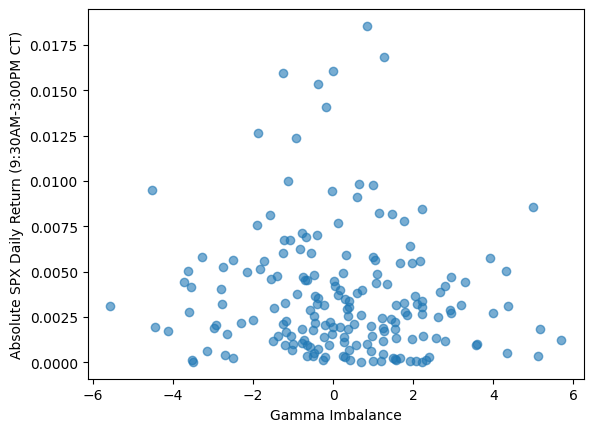

In [79]:
plot_data = reg_data[['gamma_imbl', 'abs_ret']].dropna()

plt.scatter(
    plot_data['gamma_imbl'],
    plot_data['abs_ret'],
    alpha=0.6
)

plt.xlabel('Gamma Imbalance')
plt.ylabel('Absolute SPX Daily Return (9:30AM-3:00PM CT)')
plt.show()